<>:456: SyntaxWarning: invalid escape sequence '\c'
<>:457: SyntaxWarning: invalid escape sequence '\c'
<>:456: SyntaxWarning: invalid escape sequence '\c'
<>:457: SyntaxWarning: invalid escape sequence '\c'
/var/folders/gj/gl2kb7qs563ckkg3vvvr7dvh0000gn/T/ipykernel_11214/2146475727.py:456: SyntaxWarning: invalid escape sequence '\c'
  ax1.plot(x_iters, chi2_curve, color="darkorange", lw=2, label="Pearson $\chi^2$")
/var/folders/gj/gl2kb7qs563ckkg3vvvr7dvh0000gn/T/ipykernel_11214/2146475727.py:457: SyntaxWarning: invalid escape sequence '\c'
  ax1.axhline(1.0, color="red", linestyle="--", lw=1.5, label="Target $\chi^2 = 1.0$")


[0] Immagine caricata da disco (Slice Z=12).
[0] Input: shape=(512, 512), range=[0.0000, 0.0014]
[1] Stima rumore e NLM...
[2] Calcolo Airy PSF...
[3a] FILTRO DI WIENER...
[3b] NATIVE FFT RL Standard su RAW...
[3c] NATIVE FFT RL Standard su NLM...
[3d] NATIVE FFT RL-TV (SMART Early Stopping) su RAW...
[4] Calcolo FRC...
✅ Pipeline completata.


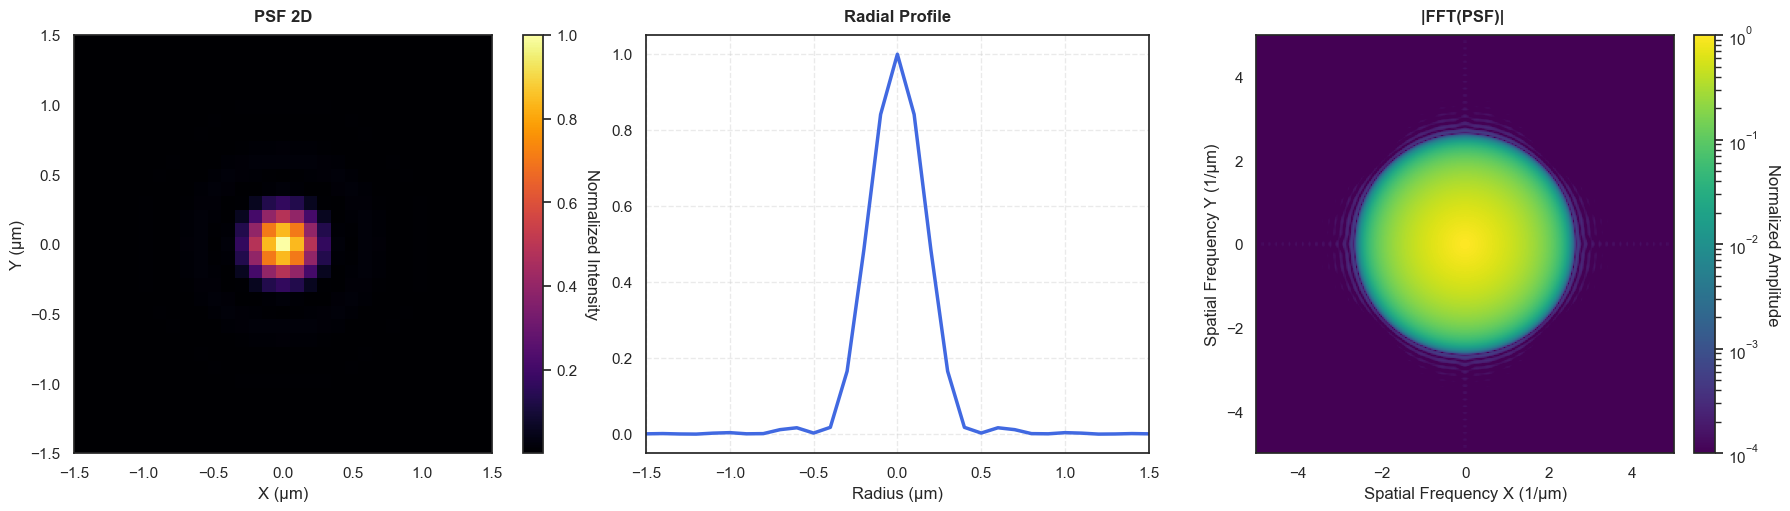

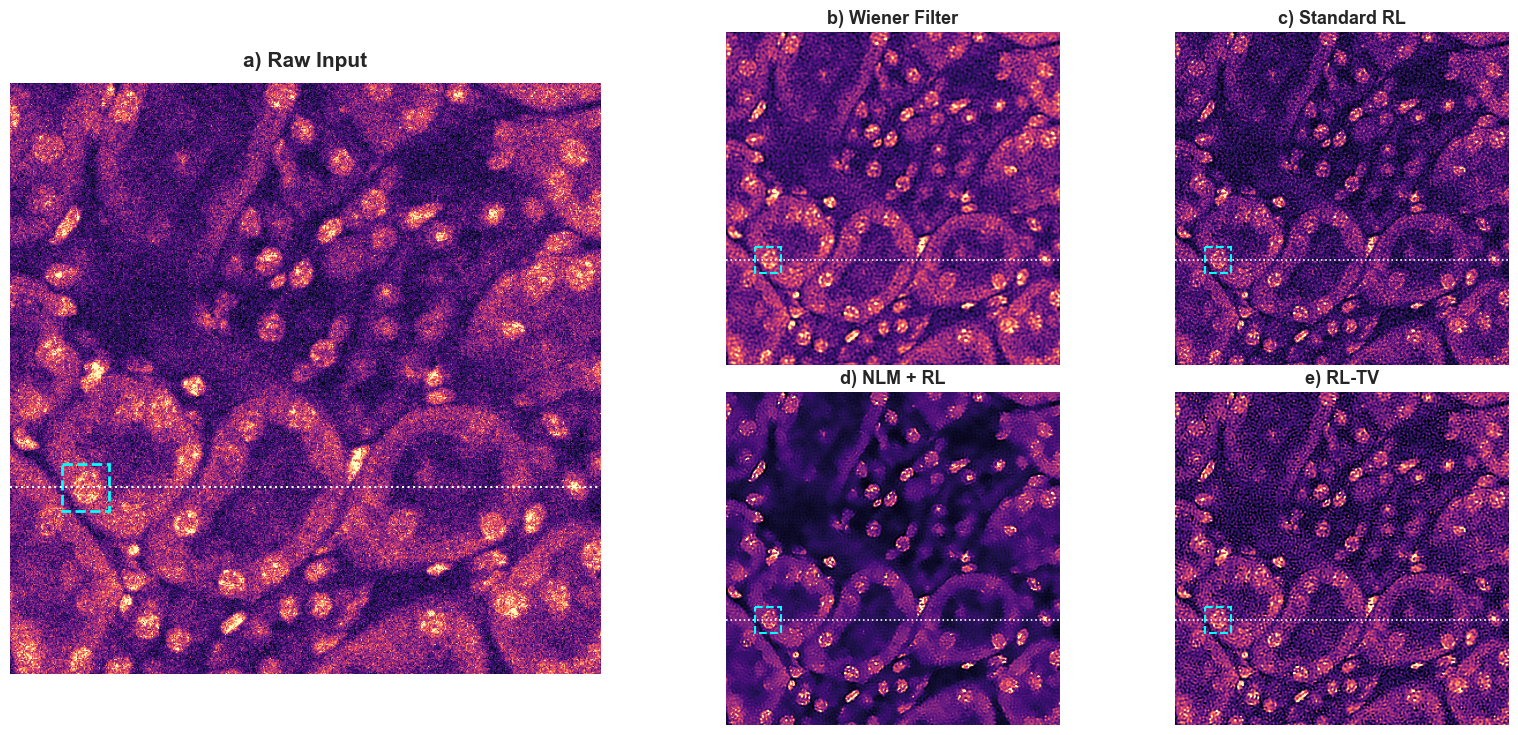

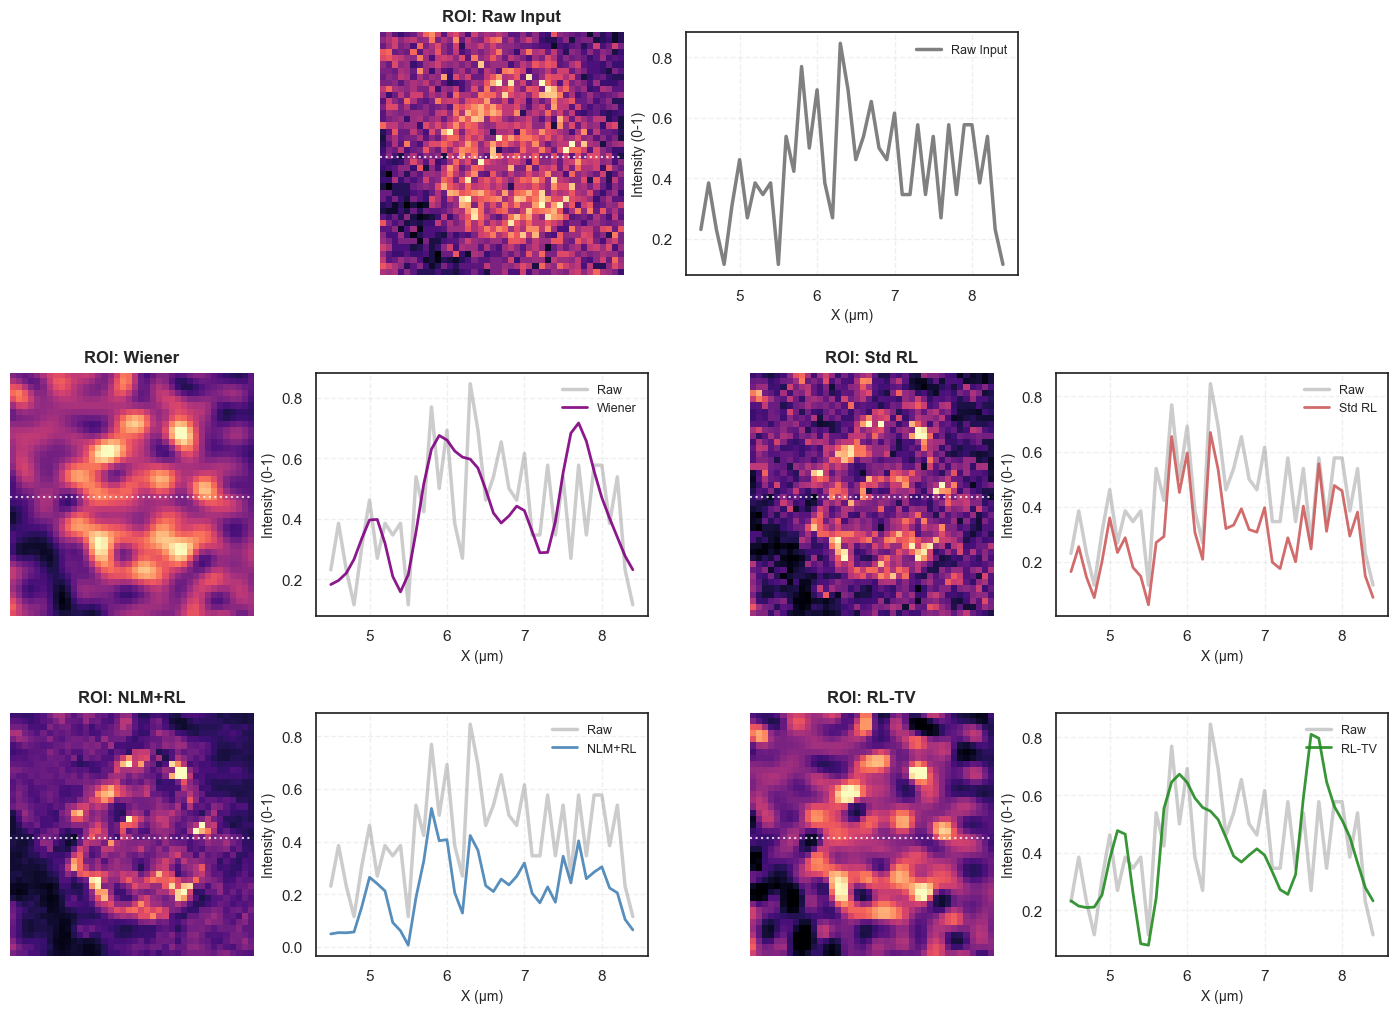

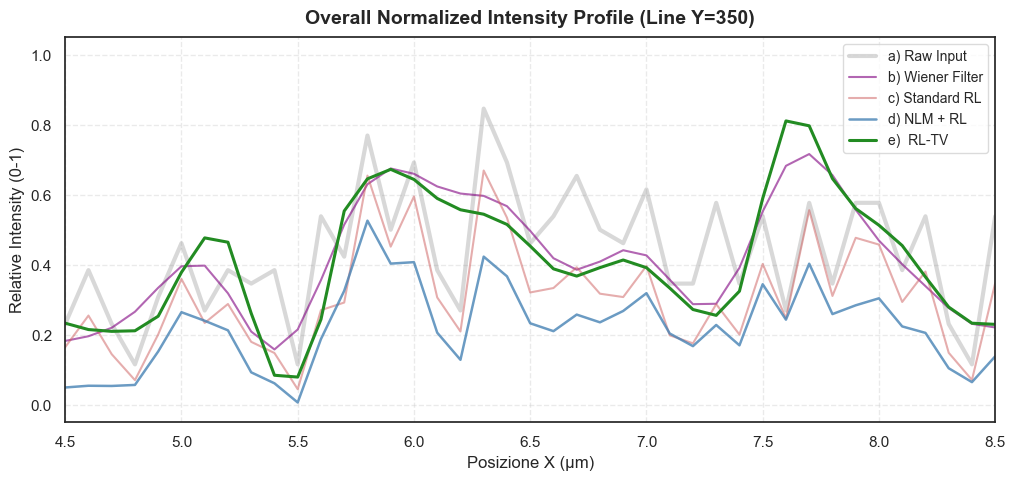

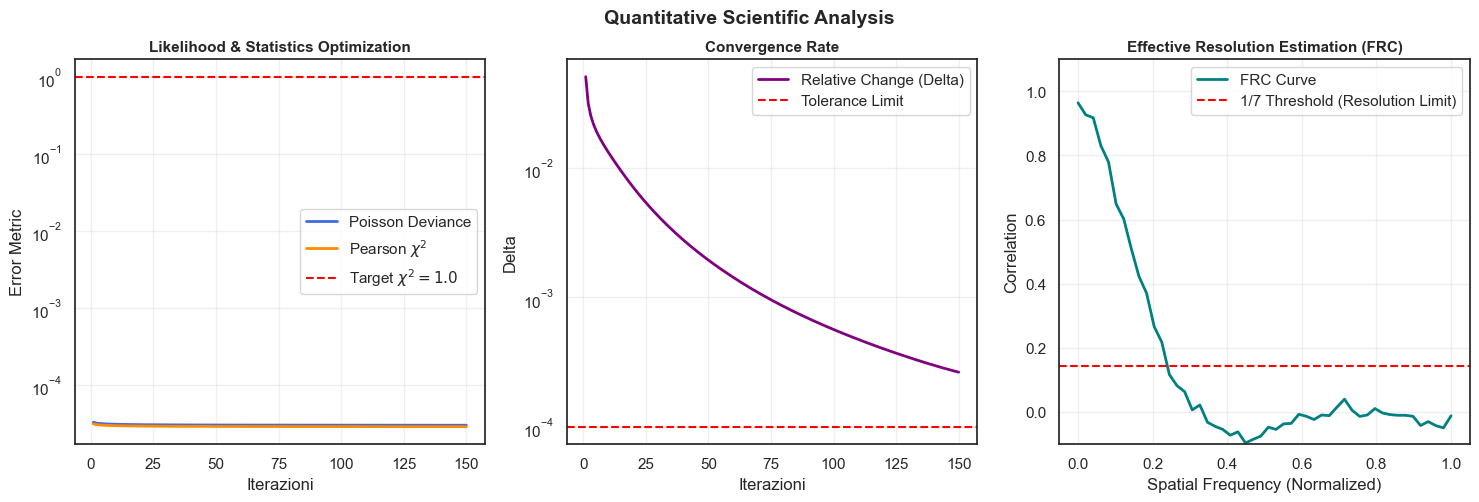

In [4]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from matplotlib.colors import LogNorm
from skimage import img_as_float, restoration
from skimage.exposure import rescale_intensity
from skimage.io import imread
from scipy.special import j1
import torch
import torch.fft
import torch.nn.functional as F

# =============================================================================
# PARAMETERS E SETUP DEVICE
# =============================================================================
MICROSCOPE = dict(NA=1.05, wavelength=0.800, ni=1.3333, pixel_size=0.100) #ni è l'indice di rifrazione del mezzo (aria)

PARAMS = dict(
    nlm_h_factor     = 0.80,
    nlm_patch        = 5,
    nlm_dist         = 6,
    psf_size         = 63,      
    wiener_balance   = 0.05,    
    rl_iters_std     = 15,      
    rl_iters_hybrid  = 35,      
    rl_max_iters_tv  = 150,     
    rl_tol           = 1e-4,    
    rl_epsilon       = 1e-8,    
    rl_tv_weight     = 0.01,    
    cmap             = "magma",
    roi              = (330, 370, 45, 85),
    profile_line     = 350,                 
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# =============================================================================
# UTILITIES FISICHE E MATEMATICHE 
# =============================================================================
def _norm_percentile(img, lo=0.1, hi=99.9):
    vmin, vmax = np.percentile(img, lo), np.percentile(img, hi)
    return rescale_intensity(img, in_range=(vmin, vmax), out_range=(0.0, 1.0))

def _scale_for_plot(arr):
    return (arr - arr.min()) / (arr.max() - arr.min() + 1e-8)

def make_airy_psf(p: dict, size: int) -> np.ndarray:
    k = 2 * np.pi * p["ni"] / p["wavelength"]
    ax = (np.arange(size) - size // 2) * p["pixel_size"]
    Y, X = np.meshgrid(ax, ax, indexing='ij')
    R = np.sqrt(X**2 + Y**2) + 1e-12 
    v = k * p["NA"] * R / p["ni"]
    psf = (2 * j1(v) / v)**2
    psf[size//2, size//2] = 1.0 
    return psf / psf.sum()

# =============================================================================
# QUANTITATIVE MICROSCOPY METRICS (POISSON)
# =============================================================================
def poisson_deviance(y: torch.Tensor, hx: torch.Tensor, eps=1e-10) -> float:
    y_safe = torch.clamp(y, min=eps)
    hx_safe = torch.clamp(hx, min=eps)
    term = y_safe * torch.log(y_safe / hx_safe) - (y_safe - hx_safe)
    return 2.0 * torch.mean(term).item()

def poisson_chi2(y: torch.Tensor, hx: torch.Tensor, eps=1e-8) -> float:
    return torch.mean((y - hx)**2 / (hx + eps)).item()

def tv_gradient(x: torch.Tensor, eps=1e-8) -> torch.Tensor:
    dx = torch.roll(x, -1, 1) - x
    dy = torch.roll(x, -1, 0) - x
    norm = torch.sqrt(dx**2 + dy**2 + eps)
    dx_norm = dx / norm
    dy_norm = dy / norm
    div = (dx_norm - torch.roll(dx_norm, 1, 1)) + (dy_norm - torch.roll(dy_norm, 1, 0))
    return div

def get_otf(psf: torch.Tensor, shape: tuple) -> torch.Tensor:
    psf_padded = torch.zeros(shape, device=psf.device)
    h, w = psf.shape
    psf_padded[:h, :w] = psf
    psf_padded = torch.roll(psf_padded, shifts=(-(h//2), -(w//2)), dims=(0, 1))
    return torch.fft.rfft2(psf_padded)

# =============================================================================
# MOTORE PYTORCH RL-TV NATIVO 
# =============================================================================
def rl_tv_fft_smart(image, psf_np, max_iters, tv_weight, tol):
    y_raw = torch.from_numpy(np.clip(image, 0, None)).float().to(device)
    psf = torch.from_numpy(psf_np).float().to(device)
    
    pad_h, pad_w = psf.shape[0] // 2, psf.shape[1] // 2
    y_pad = F.pad(y_raw.unsqueeze(0).unsqueeze(0), (pad_w, pad_w, pad_h, pad_h), mode="reflect").squeeze()
    
    otf = get_otf(psf, y_pad.shape)
    otf_conj = torch.conj(otf)
    
    x = y_pad.clone()
    
    history_dev = []
    history_chi2 = []
    history_delta = []
    stopped_at = max_iters

    for i in range(max_iters):
        x_prev = x.clone()
        
        X_f = torch.fft.rfft2(x)
        hx = torch.fft.irfft2(X_f * otf, s=y_pad.shape)
        hx = torch.clamp(hx, min=PARAMS["rl_epsilon"])
        
        hx_valid = hx[pad_h:-pad_h, pad_w:-pad_w]
        
        dev = poisson_deviance(y_raw, hx_valid)
        chi2 = poisson_chi2(y_raw, hx_valid)
        
        history_dev.append(dev)
        history_chi2.append(chi2)
        
        ratio = torch.clamp(y_pad / hx, 0.0, 5.0)
        Ratio_f = torch.fft.rfft2(ratio)
        correction = torch.fft.irfft2(Ratio_f * otf_conj, s=y_pad.shape)
        correction = torch.clamp(correction, min=0.0)
        
        if tv_weight > 0:
            tv_term = tv_gradient(x)
            denom = torch.clamp(1.0 - tv_weight * tv_term, min=1e-3)
            x = x * correction / denom
        else:
            x = x * correction
            
        x = torch.clamp(x, min=PARAMS["rl_epsilon"])
        
        x *= y_pad.sum() / (x.sum() + 1e-8)
        
        x_valid = x[pad_h:-pad_h, pad_w:-pad_w]
        x_prev_valid = x_prev[pad_h:-pad_h, pad_w:-pad_w]
        
        delta = torch.norm(x_valid - x_prev_valid) / (torch.norm(x_prev_valid) + 1e-8)
        history_delta.append(delta.item())
        
        if 0.9 <= chi2 <= 1.1 and i > 5:
            print(f"   [!] EARLY STOPPING: Pearson Chi-Square target raggiunto ({chi2:.4f}) all'iter {i+1}")
            stopped_at = i + 1
            break
            
        if delta < tol and i > 5:
            print(f"   [!] EARLY STOPPING: Convergenza limite (Delta: {delta:.6f}) all'iter {i+1}")
            stopped_at = i + 1
            break

    return x_valid.cpu().numpy(), history_dev, history_chi2, history_delta, stopped_at

# =============================================================================
# FOURIER RING CORRELATION (FRC)
# =============================================================================
def binomial_split(img: np.ndarray) -> tuple:
    photons = np.round(img * 1000).astype(int) 
    half1 = np.random.binomial(photons, 0.5)
    half2 = photons - half1
    return half1 / 1000.0, half2 / 1000.0

def compute_frc_2d(img1: np.ndarray, img2: np.ndarray, bins=50):
    F1 = np.fft.fftshift(np.fft.fft2(img1))
    F2 = np.fft.fftshift(np.fft.fft2(img2))
    Y, X = np.indices(img1.shape)
    center = np.array([img1.shape[0]//2, img1.shape[1]//2])
    R = np.round(np.sqrt((Y - center[0])**2 + (X - center[1])**2)).astype(int)
    
    frc_curve = np.zeros(bins)
    max_r = min(center)
    bin_edges = np.linspace(0, max_r, bins+1)
    
    for i in range(bins):
        mask = (R >= bin_edges[i]) & (R < bin_edges[i+1])
        if np.sum(mask) == 0: continue
        C = np.sum(F1[mask] * np.conj(F2[mask]))
        norm1 = np.sum(np.abs(F1[mask])**2)
        norm2 = np.sum(np.abs(F2[mask])**2)
        frc_curve[i] = np.real(C) / (np.sqrt(norm1 * norm2) + 1e-10)
        
    return np.linspace(0, 1, bins), frc_curve

# =============================================================================
# STEP 0 — INPUT
# =============================================================================
IMAGE_PATH = "/Users/francesco/Repositories /CNR_SNR_3channels/zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch1.tif"

if os.path.exists(IMAGE_PATH):
    stack = imread(IMAGE_PATH)
    raw_img = img_as_float(stack[11, :, :])
    print(f"[0] Immagine caricata da disco (Slice Z=12).")
else:
    print("[0] ⚠️ Generazione sintetica per test...")
    np.random.seed(42)
    y_grid, x_grid = np.mgrid[0:512, 0:512]
    raw_img = np.zeros((512, 512))
    for _ in range(60):
        cy, cx = np.random.randint(50, 460, 2)
        r = np.random.uniform(3, 8)
        raw_img += np.exp(-((x_grid - cx)**2 + (y_grid - cy)**2) / (2 * r**2))
    raw_img = rescale_intensity(raw_img, out_range=(0.1, 0.7))
    raw_img = np.random.poisson(raw_img * 100) / 100.0
    raw_img += np.random.normal(0, 0.02, raw_img.shape)
    raw_img = np.clip(raw_img, 0, 1)

print(f"[0] Input: shape={raw_img.shape}, range=[{raw_img.min():.4f}, {raw_img.max():.4f}]")
raw_norm = _norm_percentile(raw_img)

# =============================================================================
# STEP 1 — PRE-DENOISING NLM
# =============================================================================
print("[1] Stima rumore e NLM...")
sigma_est    = float(np.mean(restoration.estimate_sigma(raw_img)))
img_nlm_raw  = restoration.denoise_nl_means(
    raw_img, h=PARAMS["nlm_h_factor"] * sigma_est, fast_mode=True,
    patch_size=PARAMS["nlm_patch"], patch_distance=PARAMS["nlm_dist"])
img_nlm = np.clip(img_nlm_raw, 0, None)

# =============================================================================
# STEP 2 — DECONVOLUTION PIPELINE
# =============================================================================
print("[2] Calcolo Airy PSF...")
psf = make_airy_psf(MICROSCOPE, size=PARAMS["psf_size"])

print(f"[3a] FILTRO DI WIENER...")
img_wiener_raw = restoration.wiener(raw_img, psf, balance=PARAMS["wiener_balance"], clip=True)
img_wiener = _norm_percentile(img_wiener_raw)

print(f"[3b] NATIVE FFT RL Standard su RAW...")
img_rl_raw_pure, _, _, _, _ = rl_tv_fft_smart(raw_img, psf, PARAMS["rl_iters_std"], 0.0, PARAMS["rl_tol"])
img_rl_raw = _norm_percentile(img_rl_raw_pure)

print(f"[3c] NATIVE FFT RL Standard su NLM...")
img_rl_nlm_pure, _, _, _, _ = rl_tv_fft_smart(img_nlm, psf, PARAMS["rl_iters_hybrid"], 0.0, PARAMS["rl_tol"])
img_rl_nlm = _norm_percentile(img_rl_nlm_pure)

print(f"[3d] NATIVE FFT RL-TV (SMART Early Stopping) su RAW...")
img_rl_tv_pure, dev_curve, chi2_curve, delta_curve, iters_effettive = rl_tv_fft_smart(
    raw_img, psf, PARAMS["rl_max_iters_tv"], PARAMS["rl_tv_weight"], PARAMS["rl_tol"]
)
img_rl_tv = _norm_percentile(img_rl_tv_pure)

print("[4] Calcolo FRC...")
half1, half2 = binomial_split(raw_img)
dec_h1, _, _, _, _ = rl_tv_fft_smart(half1, psf, iters_effettive, PARAMS["rl_tv_weight"], PARAMS["rl_tol"])
dec_h2, _, _, _, _ = rl_tv_fft_smart(half2, psf, iters_effettive, PARAMS["rl_tv_weight"], PARAMS["rl_tol"])
freqs, frc_curve = compute_frc_2d(dec_h1, dec_h2)

print("✅ Pipeline completata.")

# =============================================================================
# SETUP DIRECTORY E TEMA
# =============================================================================
cartella_salvataggio = "/Users/francesco/Repositories /noise_images/IMM"
os.makedirs(cartella_salvataggio, exist_ok=True)
sns.set_theme(style="white", context="notebook", palette="deep")
pixel_size = MICROSCOPE["pixel_size"]
y0, y1, x0, x1 = PARAMS["roi"]
line_y = PARAMS["profile_line"]


# =============================================================================
# BLOCCO 1: PSF E OTF (FIX LAYOUT E ZOOM)
# =============================================================================
# Aggiunto layout="constrained" per gestire automaticamente le spaziature e le colorbar
fig1 = plt.figure(figsize=(18, 5), layout="constrained")
gs1 = fig1.add_gridspec(1, 3) 
ax_psf2d, ax_psf_rad, ax_otf = fig1.add_subplot(gs1[0]), fig1.add_subplot(gs1[1]), fig1.add_subplot(gs1[2])

size, center = psf.shape[0], psf.shape[0] // 2
ax_um = (np.arange(size) - center) * pixel_size

# --- 1. PSF 2D ---
im0 = ax_psf2d.imshow(psf / psf.max(), cmap="inferno", origin="lower", 
                      extent=[-center*pixel_size, center*pixel_size, -center*pixel_size, center*pixel_size])
ax_psf2d.set_title("PSF 2D", fontsize=12, fontweight="bold", pad=10)
ax_psf2d.set_xlabel("X (µm)")
ax_psf2d.set_ylabel("Y (µm)")

# ZOOM: Restringiamo la visuale per vedere gli anelli di diffrazione
zoom_limit = 1.5 
ax_psf2d.set_xlim(-zoom_limit, zoom_limit)
ax_psf2d.set_ylim(-zoom_limit, zoom_limit)

cbar0 = fig1.colorbar(im0, ax=ax_psf2d, fraction=0.046, pad=0.04)
cbar0.set_label("Normalized Intensity", rotation=270, labelpad=15)

# --- 2. Profilo Radiale PSF ---
ax_psf_rad.plot(ax_um, psf[center, :] / psf[center, :].max(), color="royalblue", lw=2.5)
ax_psf_rad.set_title("Radial Profile", fontsize=12, fontweight="bold", pad=10)
ax_psf_rad.set_xlabel("Radius (µm)")

# ZOOM: Applichiamo lo stesso limite anche al profilo radiale
ax_psf_rad.set_xlim(-zoom_limit, zoom_limit) 
ax_psf_rad.grid(True, alpha=0.4, linestyle="--")

# --- 3. OTF ---
pad_w = (256 - psf.shape[0]) // 2
psf_padded = np.pad(psf, pad_width=pad_w, mode='constant')
otf = np.abs(np.fft.fftshift(np.fft.fft2(psf_padded)))
otf /= otf.max()
freq_max = 1.0 / (2 * pixel_size) 

im2 = ax_otf.imshow(otf, cmap="viridis", origin="lower", 
                    extent=[-freq_max, freq_max, -freq_max, freq_max], norm=LogNorm(vmin=1e-4, vmax=1.0))
ax_otf.set_title("|FFT(PSF)| ", fontsize=12, fontweight="bold", pad=10)
ax_otf.set_xlabel("Spatial Frequency X (1/µm)")
ax_otf.set_ylabel("Spatial Frequency Y (1/µm)")

cbar2 = fig1.colorbar(im2, ax=ax_otf, fraction=0.046, pad=0.04)
cbar2.set_label("Normalized Amplitude", rotation=270, labelpad=15)

plt.savefig(os.path.join(cartella_salvataggio, "01_psf_otf.png"), dpi=300, facecolor="white")
plt.show()
# =============================================================================
# BLOCCO 2: IMMAGINI PRINCIPALI (Raw a sx più piccola, 2x2 a dx incollate)
# =============================================================================
fig2 = plt.figure(figsize=(20, 9)) 
# Usiamo width_ratios per dare più spazio alla griglia 2x2 rispetto al Raw
gs_main2 = fig2.add_gridspec(1, 2, width_ratios=[1, 1.5], wspace=0.1)

# --- a) Raw Input (Sinistra) ---
ax_raw = fig2.add_subplot(gs_main2[0])
ax_raw.imshow(raw_norm, cmap=PARAMS["cmap"], vmin=0, vmax=np.percentile(raw_norm, 99.5))
ax_raw.set_title("a) Raw Input", fontsize=15, fontweight="bold", pad=12)
ax_raw.axis("off")
ax_raw.add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0, linewidth=2, edgecolor='cyan', facecolor='none', linestyle='--'))
ax_raw.axhline(line_y, color='white', linewidth=1.5, linestyle=':', alpha=1)

# --- b) c) d) e) Griglia 2x2 (Destra) quasi incollate ---
# wspace e hspace bassissimi per l'effetto "incollato"
gs_right = gs_main2[1].subgridspec(2, 2, wspace=0.03, hspace=0.08)

ax_b = fig2.add_subplot(gs_right[0, 0])
ax_c = fig2.add_subplot(gs_right[0, 1])
ax_d = fig2.add_subplot(gs_right[1, 0])
ax_e = fig2.add_subplot(gs_right[1, 1])

stages_grid = [
    (ax_b, img_wiener, "b) Wiener Filter"),
    (ax_c, img_rl_raw, "c) Standard RL"),
    (ax_d, img_rl_nlm, "d) NLM + RL"),
    (ax_e, img_rl_tv,  "e) RL-TV")
]

for ax, img, title in stages_grid:
    ax.imshow(img, cmap=PARAMS["cmap"], vmin=0, vmax=np.percentile(img, 99.5))
    ax.set_title(title, fontsize=13, fontweight="bold", pad=6)
    ax.axis("off")
    ax.add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0, linewidth=1.5, edgecolor='cyan', facecolor='none', linestyle='--'))
    ax.axhline(line_y, color='white', linewidth=1.2, linestyle=':', alpha=1)

plt.savefig(os.path.join(cartella_salvataggio, "02_pipeline_layout.png"), dpi=300, bbox_inches="tight", facecolor="white")
plt.show()  # <-- Modificato


# =============================================================================
# BLOCCO 3: ROI E PROFILI SPECIFICI (Layout a Piramide Orizzontale)
# =============================================================================
# Figura più larga che alta per accomodare immagini e profili affiancati
fig3 = plt.figure(figsize=(18, 12)) 

# Griglia esterna: 3 righe x 4 colonne
gs_outer = fig3.add_gridspec(3, 4, wspace=0.3, hspace=0.4)

stages_all = [
    ("Raw Input", raw_norm, "gray"),
    ("Wiener", img_wiener, "purple"),
    ("Std RL", img_rl_raw, "indianred"),
    ("NLM+RL", img_rl_nlm, "steelblue"),
    ("RL-TV", img_rl_tv, "forestgreen")
]

# Slices: mappiamo i blocchi sulla griglia esterna per la struttura a piramide
slices = [
    gs_outer[0, 1:3],  # 1. Raw Input: Riga 0, centrato (occupa colonne 1 e 2)
    gs_outer[1, 0:2],  # 2. Wiener: Riga 1, sinistra (occupa colonne 0 e 1)
    gs_outer[1, 2:4],  # 3. Std RL: Riga 1, destra (occupa colonne 2 e 3)
    gs_outer[2, 0:2],  # 4. NLM+RL: Riga 2, sinistra (occupa colonne 0 e 1)
    gs_outer[2, 2:4]   # 5. RL-TV: Riga 2, destra (occupa colonne 2 e 3)
]

asse_x_roi = np.arange(x0, x1) * pixel_size
roi_line_y = line_y - y0 

raw_profile_roi = _scale_for_plot(raw_norm[line_y, :])[x0:x1]

for i, ((name, img, color), gs_slice) in enumerate(zip(stages_all, slices)):
    
    # Subgridspec interno: 1 RIGA, 2 COLONNE (Immagine a sinistra, Profilo a destra)
    gs_inner = gs_slice.subgridspec(1, 2, width_ratios=[1, 1.2], wspace=0.15)
    
    # Setup asse Immagine ROI (Sinistra)
    ax_roi = fig3.add_subplot(gs_inner[0])
    crop = img[y0:y1, x0:x1]
    ax_roi.imshow(crop, cmap=PARAMS["cmap"], vmin=0, vmax=np.percentile(crop, 99.5))
    ax_roi.set_title(f"ROI: {name}", fontsize=12, fontweight="bold", pad=8)
    ax_roi.axis("off")
    ax_roi.axhline(roi_line_y, color='white', linewidth=1.5, linestyle=':', alpha=0.8)

    # Setup asse Profilo Individuale (Destra)
    ax_prof_ind = fig3.add_subplot(gs_inner[1])
    img_profile_roi = _scale_for_plot(img[line_y, :])[x0:x1]
    
    if i == 0:
        ax_prof_ind.plot(asse_x_roi, raw_profile_roi, color=color, lw=2.5, label=name)
    else:
        ax_prof_ind.plot(asse_x_roi, raw_profile_roi, color="gray", alpha=0.4, lw=2.5, label="Raw")
        ax_prof_ind.plot(asse_x_roi, img_profile_roi, color=color, alpha=0.9, lw=2.0, label=name)
        
    # Applichiamo le etichette degli assi a TUTTI i grafici
    ax_prof_ind.set_xlabel("X (µm)", fontsize=10)
    ax_prof_ind.set_ylabel("Intensity (0-1)", fontsize=10)
        
    ax_prof_ind.legend(loc="upper right", frameon=False, fontsize=9)
    ax_prof_ind.grid(True, alpha=0.3, linestyle="--")

plt.savefig(os.path.join(cartella_salvataggio, "03_rois_and_profiles.png"), dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
# =============================================================================
# BLOCCO 4: OVERALL INTENSITY PROFILE ALONG ROI
# =============================================================================
fig4, ax_overall = plt.subplots(figsize=(12, 5))

asse_x_um = np.arange(raw_norm.shape[1]) * pixel_size

ax_overall.plot(asse_x_um, _scale_for_plot(raw_norm[line_y, :]), color="gray", alpha=0.3, lw=3.0, label="a) Raw Input")
ax_overall.plot(asse_x_um, _scale_for_plot(img_wiener[line_y, :]), color="purple",      alpha=0.6, lw=1.5, label="b) Wiener Filter")
ax_overall.plot(asse_x_um, _scale_for_plot(img_rl_raw[line_y, :]), color="indianred",   alpha=0.5, lw=1.5, label="c) Standard RL")
ax_overall.plot(asse_x_um, _scale_for_plot(img_rl_nlm[line_y, :]), color="steelblue",   alpha=0.8, lw=1.8, label="d) NLM + RL")
ax_overall.plot(asse_x_um, _scale_for_plot(img_rl_tv[line_y, :]),  color="forestgreen", alpha=1.0, lw=2.2, label="e)  RL-TV")

ax_overall.set_title(f"Overall Normalized Intensity Profile (Line Y={line_y})", fontsize=14, fontweight="bold", pad=10)
ax_overall.set_xlabel("Posizione X (µm)", fontsize=12)
ax_overall.set_ylabel("Relative Intensity (0-1)", fontsize=12)
ax_overall.legend(frameon=True, facecolor="white", edgecolor="lightgray", fontsize=10, loc='upper right')
ax_overall.grid(True, alpha=0.4, linestyle="--")
ax_overall.set_xlim(x0 * pixel_size, x1 * pixel_size) 

plt.savefig(os.path.join(cartella_salvataggio, "04_overall_profile.png"), dpi=300, bbox_inches="tight", facecolor="white")
plt.show()  # <-- Modificato


# =============================================================================
# BLOCCO 5: ADVANCED SCIENTIFIC DASHBOARD (FRC e Metriche)
# =============================================================================
fig5, axes = plt.subplots(1, 3, figsize=(18, 5))
fig5.suptitle("Quantitative Scientific Analysis", fontsize=14, fontweight="bold")

x_iters = np.arange(1, len(dev_curve) + 1)
ax1 = axes[0]
ax1.plot(x_iters, dev_curve, color="royalblue", lw=2, label="Poisson Deviance")
ax1.plot(x_iters, chi2_curve, color="darkorange", lw=2, label="Pearson $\chi^2$")
ax1.axhline(1.0, color="red", linestyle="--", lw=1.5, label="Target $\chi^2 = 1.0$")
ax1.set_title("Likelihood & Statistics Optimization", fontsize=11, fontweight="bold")
ax1.set_xlabel("Iterazioni")
ax1.set_ylabel("Error Metric")
ax1.set_yscale("log")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2 = axes[1]
ax2.plot(x_iters, delta_curve, color="purple", lw=2, label="Relative Change (Delta)")
ax2.axhline(PARAMS["rl_tol"], color="red", linestyle="--", lw=1.5, label="Tolerance Limit")
ax2.set_title("Convergence Rate", fontsize=11, fontweight="bold")
ax2.set_xlabel("Iterazioni")
ax2.set_ylabel("Delta")
ax2.set_yscale("log")
ax2.legend()
ax2.grid(True, alpha=0.3)

ax3 = axes[2]
ax3.plot(freqs, frc_curve, color="teal", lw=2, label="FRC Curve")
ax3.axhline(1/7, color="red", linestyle="--", lw=1.5, label="1/7 Threshold (Resolution Limit)")
ax3.set_ylim(-0.1, 1.1)
ax3.set_title("Effective Resolution Estimation (FRC)", fontsize=11, fontweight="bold")
ax3.set_xlabel("Spatial Frequency (Normalized)")
ax3.set_ylabel("Correlation")
ax3.legend()
ax3.grid(True, alpha=0.3)

plt.savefig(os.path.join(cartella_salvataggio, "05_quantitative_analysis.png"), dpi=300, bbox_inches="tight", facecolor="white")
plt.show()  # <-- Modificato

[SETUP] Backend: CPU (Forzato per supporto FFT/ComplexFloat su Mac)
[LOAD] File 'zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch1.tif' caricato — shape: (512, 512)
[PHYSICS] Backend: CPU

[PRE] Non-Local Means denoising (immagine intera)...

[RUN] Wiener  (balance=0.05, step=singolo)
    → Stopped at iter 1

[RUN] RL Standard  (λ_TV=0.0, max_iters=200)
    → Stopped at iter 200

[RUN] NLM + RL  (λ_TV=0.0, max_iters=200)
    → Stopped at iter 200

[RUN] RL-TV  (λ_TV=0.01, max_iters=200)
    → Stopped at iter 200

[SAVE] Dashboard salvata: /Users/francesco/Repositories /noise_images/IMM/frc_comparative_dashboard.png


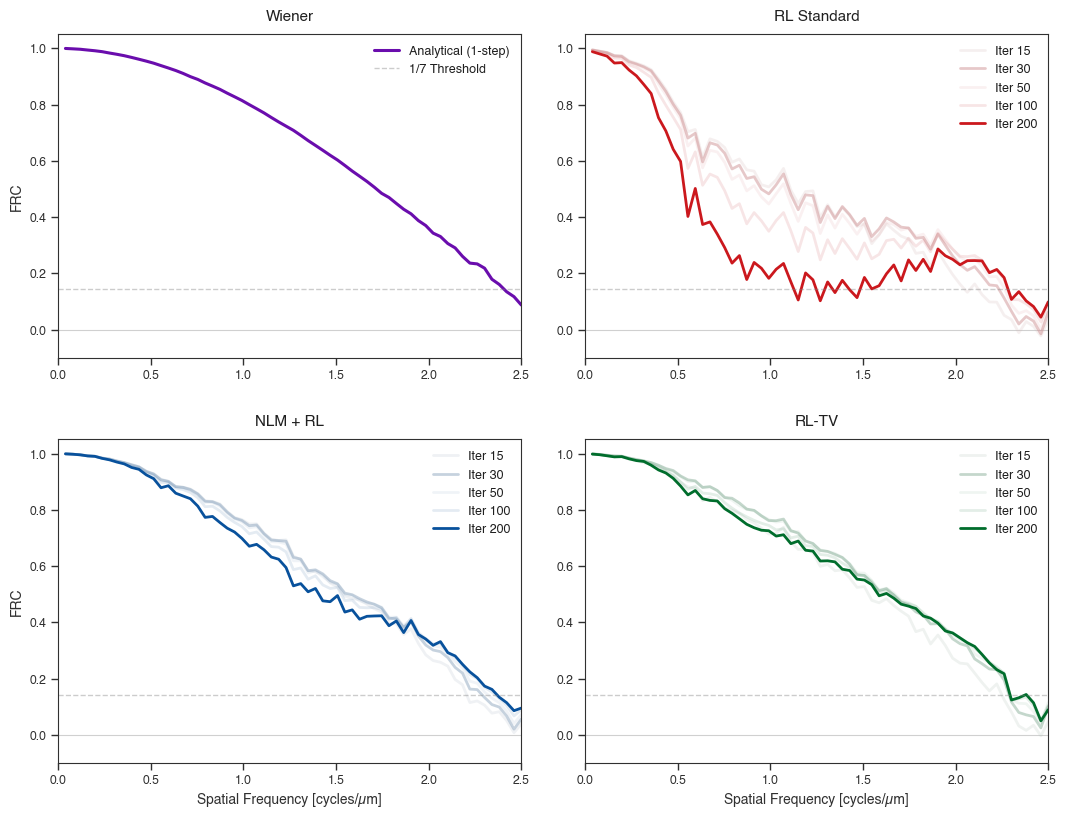

In [2]:
"""
================================================================================
FRC-GUIDED COMPARATIVE DECONVOLUTION ANALYSIS — DIGITAL HOLOGRAPHIC MICROSCOPY
================================================================================
Fusione rigorosa tra:
  - Gestione fisica dell'OTF (ifftshift zero-fase, PSF Airy analitica)
  - One-Image FRC (Koho et al., 2019) tramite Checkerboard Spatial Split 
  - Motore RL-TV con conservazione MLE Poissoniana esatta e padding sicuro
  - Filtro Analitico di Wiener (Baseline a singolo step)
  - Visualizzazione Publication-Ready (Seaborn, Minimal, Gradients, Boxed Axes)
================================================================================
"""

import os
import warnings
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.special import j1
from skimage import img_as_float, restoration
from skimage.exposure import rescale_intensity
from skimage.io import imread
import torch
import torch.fft
import torch.nn.functional as F

warnings.filterwarnings("ignore")

# =============================================================================
# CONFIGURAZIONE GLOBALE
# =============================================================================
MICROSCOPE = dict(
    NA          = 1.05,      
    wavelength  = 0.770,    
    ni          = 1.3333,    
    pixel_size  = 0.100,    
)

PARAMS = dict(
    nlm_h_factor     = 0.80,
    nlm_patch        = 5,
    nlm_dist         = 6,
    psf_size         = 63,
    rl_epsilon       = 1e-8,
    rl_tol           = 1e-4,
    rl_tv_weight     = 0.01,
    pad_size         = 64,
    wiener_balance   = 0.05,        
    frc_bins         = 64,
    frc_threshold    = 1.0 / 7.0,
    frc_min_pixels   = 12,          
    iter_checkpoints = [15, 30, 50, 100, 200],
)

# =============================================================================
# 1. MODULO FISICO: PSF AIRY ANALITICA + OTF ZERO-FASE
# =============================================================================
class PhysicsCore:
    def __init__(self, microscope: dict):
        self.dx  = microscope["pixel_size"]
        self.NA  = microscope["NA"]
        self.wl  = microscope["wavelength"]
        self.ni  = microscope["ni"]
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        print(f"[PHYSICS] Backend: {'CUDA' if self.device.type == 'cuda' else 'CPU'}")

    def make_airy_psf(self, size: int) -> np.ndarray:
        k  = 2.0 * np.pi * self.ni / self.wl
        ax = (np.arange(size) - size // 2) * self.dx
        Y, X = np.meshgrid(ax, ax, indexing="ij")
        R = np.sqrt(X**2 + Y**2) + 1e-12
        v = k * self.NA * R / self.ni
        psf = (2.0 * j1(v) / v) ** 2
        psf[size // 2, size // 2] = 1.0 
        return (psf / psf.sum()).astype(np.float32)

    def psf_to_otf(self, psf_np: np.ndarray, target_shape: tuple) -> torch.Tensor:
        H, W = target_shape
        h, w = psf_np.shape
        psf_t = torch.from_numpy(psf_np).float().to(self.device)

        canvas = torch.zeros(H, W, device=self.device)
        ph, pw = (H - h) // 2, (W - w) // 2
        canvas[ph : ph + h, pw : pw + w] = psf_t

        canvas = torch.fft.ifftshift(canvas)
        return torch.fft.rfft2(canvas)

# =============================================================================
# 2. FOURIER RING CORRELATION — KOHO SPATIAL SPLIT (One-Image FRC)
# =============================================================================
class KohoSpatialFRC:
    def __init__(self, microscope: dict, bins: int = 64, min_pixels: int = 12):
        self.dx         = microscope["pixel_size"]
        self.bins       = bins
        self.min_pixels = min_pixels
        self.threshold  = 1.0 / 7.0
        self.device     = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    def measure(self, img: np.ndarray):
        img_t = torch.from_numpy(img).float().to(self.device)

        h, w = img_t.shape
        img_c = img_t[:h - (h % 2), :w - (w % 2)]

        s1_1, s1_2 = img_c[0::2, 0::2], img_c[1::2, 1::2]
        s2_1, s2_2 = img_c[0::2, 1::2], img_c[1::2, 0::2]

        freqs, frc1 = self._compute_frc_spectra(s1_1, s1_2)
        _    , frc2 = self._compute_frc_spectra(s2_1, s2_2)

        frc_mean = ((frc1 + frc2) / 2.0).cpu().numpy()
        frc_std  = np.zeros_like(frc_mean) 

        return freqs, frc_mean, frc_std

    def _compute_frc_spectra(self, img1: torch.Tensor, img2: torch.Tensor):
        h, w = img1.shape
        wy = torch.hamming_window(h, periodic=False, device=self.device).unsqueeze(1)
        wx = torch.hamming_window(w, periodic=False, device=self.device).unsqueeze(0)
        win = wy * wx

        F1 = torch.fft.fft2(img1 * win)
        F2 = torch.fft.fft2(img2 * win)

        fy = torch.fft.fftfreq(h, device=self.device)
        fx = torch.fft.fftfreq(w, device=self.device)
        FY, FX = torch.meshgrid(fy, fx, indexing="ij")
        K = torch.sqrt(FX**2 + FY**2).flatten()

        F1f, F2f = F1.flatten(), F2.flatten()
        edges = torch.linspace(0.0, 0.5, self.bins + 1, device=self.device)
        idx   = torch.bucketize(K, edges, right=True) - 1

        frc = torch.full((self.bins,), float("nan"), device=self.device)
        for b in range(self.bins):
            mask = idx == b
            if mask.sum() < self.min_pixels:
                continue
            C  = torch.sum(F1f[mask] * torch.conj(F2f[mask]))
            N1 = torch.sum(torch.abs(F1f[mask]) ** 2)
            N2 = torch.sum(torch.abs(F2f[mask]) ** 2)
            denom = torch.sqrt(N1 * N2)
            frc[b] = torch.real(C) / denom if denom > 1e-12 else 0.0

        dx_eff = 2.0 * self.dx
        f_max = 1.0 / (2.0 * dx_eff)
        freqs_um = np.linspace(0.0, f_max, self.bins)

        return freqs_um, frc

# =============================================================================
# 3. MOTORE RICHARDSON-LUCY ± TOTAL VARIATION
# =============================================================================
class RLTVEngine:
    def __init__(self, physics: PhysicsCore):
        self.physics = physics
        self.device  = physics.device
        self.eps     = PARAMS["rl_epsilon"]
        self.pad     = PARAMS["pad_size"]

    def _tv_gradient(self, x: torch.Tensor, eps: float = 1e-8) -> torch.Tensor:
        dx   = torch.roll(x, -1, 1) - x
        dy   = torch.roll(x, -1, 0) - x
        norm = torch.sqrt(dx**2 + dy**2 + eps)
        divx = dx / norm - torch.roll(dx / norm, 1, 1)
        divy = dy / norm - torch.roll(dy / norm, 1, 0)
        return divx + divy

    def deconvolve(self, image: np.ndarray, psf_np: np.ndarray, n_iters: int,
                   tv_weight: float = 0.0, checkpoints: list = None, tol: float = 1e-4) -> dict:
        if checkpoints is None: checkpoints = []

        pad = self.pad
        y   = torch.from_numpy(np.clip(image, 0, None)).float().to(self.device)
        y_pad = F.pad(y.unsqueeze(0).unsqueeze(0), (pad, pad, pad, pad), mode="reflect").squeeze()

        otf      = self.physics.psf_to_otf(psf_np, y_pad.shape)
        otf_conj = torch.conj(otf)

        x            = y_pad.clone()
        flux_target  = y_pad.sum()
        snapshots    = {}
        stopped_at   = n_iters

        for i in range(1, n_iters + 1):
            x_prev = x.clone()

            Hx = torch.fft.irfft2(torch.fft.rfft2(x) * otf, s=y_pad.shape)
            Hx = torch.clamp(Hx, min=self.eps)

            ratio      = y_pad / Hx
            correction = torch.fft.irfft2(torch.fft.rfft2(ratio) * otf_conj, s=y_pad.shape)
            correction = torch.clamp(correction, min=0.0)

            if tv_weight > 0.0:
                denom = torch.clamp(1.0 - tv_weight * self._tv_gradient(x), min=1e-2)
                x = x * correction / denom
            else:
                x = x * correction

            x = F.relu(x)
            cs = x.sum()
            if cs > 1e-12:
                x = x * (flux_target / cs)

            x_v  = x[pad:-pad, pad:-pad]
            xp_v = x_prev[pad:-pad, pad:-pad]
            delta = (torch.norm(x_v - xp_v) / (torch.norm(xp_v) + 1e-8)).item()

            if i in checkpoints:
                snapshots[i] = x_v.cpu().numpy().copy()

            if delta < tol and i > 5:
                stopped_at = i
                last = x_v.cpu().numpy().copy()
                for ck in checkpoints:
                    if ck not in snapshots: snapshots[ck] = last
                break

        last = x[pad:-pad, pad:-pad].cpu().numpy().copy()
        for ck in checkpoints:
            if ck not in snapshots: snapshots[ck] = last

        return {"snapshots": snapshots, "stopped_at": stopped_at}

# =============================================================================
# 4. PIPELINE COMPARATIVA RIGOROSA (CON WIENER)
# =============================================================================
def run_comparative_pipeline(raw_img: np.ndarray, psf_np: np.ndarray, checkpoints: list, 
                             physics: PhysicsCore, frc_engine: KohoSpatialFRC) -> dict:
    engine  = RLTVEngine(physics)
    results = {}
    max_iters = max(checkpoints)

    print("\n[PRE] Non-Local Means denoising (immagine intera)...")
    sigma_est = float(np.mean(restoration.estimate_sigma(raw_img)))
    h_nlm     = PARAMS["nlm_h_factor"] * sigma_est
    img_nlm   = np.clip(restoration.denoise_nl_means(
                    raw_img, h=h_nlm, fast_mode=True,
                    patch_size=PARAMS["nlm_patch"], patch_distance=PARAMS["nlm_dist"]
                ), 0, None)

    methods = {
        "Wiener"      : (raw_img, None, "wiener"), 
        "RL Standard" : (raw_img, 0.0, "rl"),
        "NLM + RL"    : (img_nlm, 0.0, "rl"),
        "RL-TV"       : (raw_img, PARAMS["rl_tv_weight"], "rl"),
    }

    for name, (inp_full, param, m_type) in methods.items():
        if m_type == "wiener":
            print(f"\n[RUN] {name}  (balance={PARAMS['wiener_balance']}, step=singolo)")
            out_img = restoration.wiener(inp_full, psf_np, balance=PARAMS["wiener_balance"], clip=True)
            out_full_dict = {
                "stopped_at": 1,
                "snapshots": {ck: out_img for ck in checkpoints}
            }
        else:
            print(f"\n[RUN] {name}  (λ_TV={param}, max_iters={max_iters})")
            out_full_dict = engine.deconvolve(inp_full, psf_np, max_iters, tv_weight=param, checkpoints=checkpoints, tol=PARAMS["rl_tol"])
        
        print(f"    → Stopped at iter {out_full_dict['stopped_at']}")

        method_data = {}
        for ck in checkpoints:
            img_ck = out_full_dict["snapshots"][ck]
            
            freqs_um, frc_mean, frc_std = frc_engine.measure(img_ck)
            method_data[ck] = dict(img=img_ck, freqs_um=freqs_um, frc_mean=frc_mean, frc_std=frc_std)
            
        results[name] = method_data

    return results

# =============================================================================
# 5. VISUALIZZAZIONE SCIENTIFICA — PUBLICATION-READY DASHBOARD
# =============================================================================
def plot_frc_dashboard(results: dict, checkpoints: list, save_dir: str = ".", filename: str = "frc_comparative_dashboard.png", dpi: int = 300) -> None:
    """
    Dashboard in stile Nature/Optics Express.
    - Sfondo bianco pulito (white / ticks)
    - Gradienti di palette per le iterazioni
    - Linee sottili, niente grid, assi chiusi su tutti e 4 i lati.
    """
    # 1. Configurazione Tema Globale Seaborn & Matplotlib
    sns.set_theme(style="ticks", context="paper")
    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
        "axes.linewidth": 0.8,
        "axes.edgecolor": "#303030",      # Bordo leggermente più scuro e netto
        "xtick.color": "#303030",
        "ytick.color": "#303030",
        "text.color": "#202020",
        "axes.labelcolor": "#303030",
    })

    methods = list(results.keys())
    thr = PARAMS["frc_threshold"]
    
    fig, axes = plt.subplots(2, 2, figsize=(11, 8.5))
    axes = axes.flatten()
    


    def get_optimized_palette(color_full, n):
        # Definiamo i pesi: 15 (più scuro), 30, 50, 100 (sfumati), 200 (pieno)
        # Sostituiamo il bianco puro con un grigio chiaro per la base (15)
        # e usiamo una palette che stringe il range per le intermedie
        base_light = "#d1d1d1" # Base per Iter 15 (più visibile)
        steps = sns.blend_palette([base_light, color_full], n_colors=7)
        # Selezioniamo: 15=idx 1, 30=idx 2, 50=idx 3, 100=idx 4, 200=idx 6
        return [steps[1], steps[2], steps[3], steps[4], color_full]

    palettes = {
        "Wiener":      sns.blend_palette(["#d1d1d1", "#6a0dad"], n_colors=len(checkpoints)),
        "RL Standard": get_optimized_palette("#cb181d", len(checkpoints)),
        "NLM + RL":    get_optimized_palette("#08519c", len(checkpoints)),
        "RL-TV":       get_optimized_palette("#006d2c", len(checkpoints)),
    }
    
    for i, method in enumerate(methods):
        ax = axes[i]
        method_pal = palettes[method]
        
        # Ci assicuriamo che gli assi top e right siano visibili (chiudiamo il grafico)
        for spine in ax.spines.values():
            spine.set_visible(True)
            
        if method == "Wiener":
            # Wiener è single-step, usiamo il colore più intenso del gradiente
            d = results[method][checkpoints[-1]]
            freqs = d["freqs_um"]
            frc_mean = d["frc_mean"]
            frc_std = d["frc_std"]
            
            c = method_pal[-1]
            ax.plot(freqs, frc_mean, color=c, lw=2.2, label="Analytical (1-step)")
            if np.any(frc_std > 0):
                ax.fill_between(freqs, frc_mean - frc_std, frc_mean + frc_std, color=c, alpha=0.15, lw=0)
        else:
            # Per i metodi iterativi
            for j, ck in enumerate(checkpoints):
                d = results[method][ck]
                freqs = d["freqs_um"]
                frc_mean = d["frc_mean"]
                frc_std = d["frc_std"]
                
                c = method_pal[j]
            
                # Mappiamo le tue richieste di alpha:
                # 15=0.2, 30=0.5, 50=0.10, 100=0.15, 200=1.0
                alpha_values = [0.2, 0.5, 0.10, 0.15, 1.0]
                
                # Applichiamo il valore specifico
                current_alpha = alpha_values[j]
                
                # Plot con alpha personalizzato
                ax.plot(freqs, frc_mean, color=c, lw=2.0, alpha=current_alpha, label=f"Iter {ck}")
                
                # Fill_between basato sull'alpha scelto per non appesantire il grafico
                if np.any(frc_std > 0):
                    ax.fill_between(freqs, frc_mean - frc_std, frc_mean + frc_std, 
                                    color=c, alpha=current_alpha * 0.2, lw=0)
        
        # 3. Linee Guida (Threshold FRC)
        ax.axhline(thr, color="#808080", lw=1.0, ls="--", alpha=0.4, label="1/7 Threshold" if i == 0 else "")
        ax.axhline(0, color="#d0d0d0", lw=0.8, ls="-", zorder=0)
        
        # 4. Formattazione degli Assi
        ax.set_title(method, fontsize=11, fontweight="semibold", pad=10, loc="center")
        
        if i >= 2: # Solo per i subplot inferiori
            ax.set_xlabel("Spatial Frequency [cycles/µm]", fontsize=10)
        if i % 2 == 0: # Solo per i subplot a sinistra
            ax.set_ylabel("FRC", fontsize=10)
            
        ax.set_ylim(-0.1, 1.05)
        freqs_max = results[method][checkpoints[-1]]["freqs_um"][-1]
        ax.set_xlim(0, freqs_max)
        
        # Rimuoviamo la griglia retrostante
        ax.grid(False)
        
        # Legenda pulita e trasparente
        handles, labels = ax.get_legend_handles_labels()
        if handles:
            by_label = dict(zip(labels, handles)) # Rimuove eventuali duplicati
            ax.legend(by_label.values(), by_label.keys(), 
                      frameon=False, loc="upper right", fontsize=9, borderaxespad=0.5)

    # 5. Ritocchi Finali
    plt.tight_layout(pad=2.0, h_pad=2.5, w_pad=2.0)
    
    os.makedirs(save_dir, exist_ok=True)
    out_path = os.path.join(save_dir, filename)
    plt.savefig(out_path, dpi=dpi, bbox_inches="tight", transparent=False)
    print(f"\n[SAVE] Dashboard salvata: {out_path}")
    plt.show()

# =============================================================================
# 6. CARICAMENTO DATI E ENTRY POINT
# =============================================================================
def load_image(path: str, z_slice: int = 11) -> np.ndarray:
    if os.path.exists(path):
        stack = imread(path)
        raw = img_as_float(stack[z_slice] if stack.ndim == 3 else stack).astype(np.float32)
        print(f"[LOAD] File '{os.path.basename(path)}' caricato — shape: {raw.shape}")
        return raw
    else:
        raise FileNotFoundError(f"File {path} non trovato!")

def main():
    if torch.cuda.is_available():
        device = torch.device("cuda")
        print("[SETUP] Backend: NVIDIA CUDA")
    else:
        device = torch.device("cpu")
        print("[SETUP] Backend: CPU (Forzato per supporto FFT/ComplexFloat su Mac)")

    IMAGE_PATH  = "/Users/francesco/Repositories /CNR_SNR_3channels/zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch1.tif"
    SAVE_DIR    = "/Users/francesco/Repositories /noise_images/IMM"
    Z_SLICE     = 11
    CHECKPOINTS = PARAMS["iter_checkpoints"]

    raw_img = load_image(IMAGE_PATH, z_slice=Z_SLICE)
    vmin, vmax = np.percentile(raw_img, 0.1), np.percentile(raw_img, 99.9)
    raw_img = rescale_intensity(raw_img, in_range=(vmin, vmax), out_range=(0.0, 1.0))

    physics = PhysicsCore(MICROSCOPE)
    physics.device = device
    
    psf_np  = physics.make_airy_psf(size=PARAMS["psf_size"])
    
    frc_engine = KohoSpatialFRC(microscope=MICROSCOPE, bins=PARAMS["frc_bins"], min_pixels=PARAMS["frc_min_pixels"])
    frc_engine.device = device

    results = run_comparative_pipeline(raw_img, psf_np, CHECKPOINTS, physics, frc_engine)
    
    plot_frc_dashboard(results=results, checkpoints=CHECKPOINTS, save_dir=SAVE_DIR)

if __name__ == "__main__":
    main()

In [3]:
# Riesegue la pipeline e stampa i cutoff FRC
_physics = PhysicsCore(MICROSCOPE)
_psf_np  = _physics.make_airy_psf(size=PARAMS["psf_size"])
_frc_engine = KohoSpatialFRC(microscope=MICROSCOPE, bins=PARAMS["frc_bins"], min_pixels=PARAMS["frc_min_pixels"])

_raw_img = load_image(
    "/Users/francesco/Repositories /CNR_SNR_3channels/zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch1.tif",
    z_slice=11
)
_vmin, _vmax = np.percentile(_raw_img, 0.1), np.percentile(_raw_img, 99.9)
_raw_img = rescale_intensity(_raw_img, in_range=(_vmin, _vmax), out_range=(0.0, 1.0))

results = run_comparative_pipeline(_raw_img, _psf_np, PARAMS["iter_checkpoints"], _physics, _frc_engine)

# --- Estrazione cutoff ---
thr = 1.0 / 7.0

def find_cutoff(freqs, frc_curve):
    frc_clean = np.nan_to_num(frc_curve, nan=1.0)
    below = np.where(frc_clean < thr)[0]
    return freqs[below[0]] if len(below) > 0 else freqs[-1]

print("=" * 60)
print("FRC CUTOFF f_c [cycles/µm] @ 1/7 threshold")
print("=" * 60)
header = f"{'Method':<15}" + "".join([f"  Iter {ck:>3}" for ck in PARAMS["iter_checkpoints"]])
print(header)
print("-" * 60)
for method, method_data in results.items():
    row = f"{method:<15}"
    for ck in PARAMS["iter_checkpoints"]:
        fc = find_cutoff(method_data[ck]["freqs_um"], method_data[ck]["frc_mean"])
        row += f"  {fc:>7.3f}"
    print(row)

print()
print("=" * 60)
print("CUTOFF ITER 200 — per tabella LaTeX")
print("=" * 60)
for method, method_data in results.items():
    last_ck = max(method_data.keys())
    fc = find_cutoff(method_data[last_ck]["freqs_um"], method_data[last_ck]["frc_mean"])
    print(f"  {method:<15} → f_c = {fc:.3f} cycles/µm")

[PHYSICS] Backend: CPU
[LOAD] File 'zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch1.tif' caricato — shape: (512, 512)

[PRE] Non-Local Means denoising (immagine intera)...

[RUN] Wiener  (balance=0.05, step=singolo)
    → Stopped at iter 1

[RUN] RL Standard  (λ_TV=0.0, max_iters=200)
    → Stopped at iter 200

[RUN] NLM + RL  (λ_TV=0.0, max_iters=200)
    → Stopped at iter 200

[RUN] RL-TV  (λ_TV=0.01, max_iters=200)
    → Stopped at iter 200
FRC CUTOFF f_c [cycles/µm] @ 1/7 threshold
Method           Iter  15  Iter  30  Iter  50  Iter 100  Iter 200
------------------------------------------------------------
Wiener             2.421    2.421    2.421    2.421    2.421
RL Standard        2.063    2.262    2.302    2.302    1.151
NLM + RL           2.222    2.302    2.341    2.381    2.381
RL-TV              2.262    2.302    2.302    2.302    2.302

CUTOFF ITER 200 — per tabella LaTeX
  Wiener          → f_c = 2.421 cycles/µm
  RL Standard     → f_c = 1.151 cycles/µm
  NLM + 

── Metrics ──────────────────────────────────────────────────
  Raw         SNR_rel=1.00x  CNR_rel=1.00x  FWHM=2.300 µm
  Wiener      SNR_rel=1.67x  CNR_rel=1.62x  FWHM=2.283 µm
  Std RL      SNR_rel=0.80x  CNR_rel=0.81x  FWHM=2.278 µm
  NLM+RL      SNR_rel=4.91x  CNR_rel=5.60x  FWHM=2.152 µm
  RL-TV       SNR_rel=0.78x  CNR_rel=0.80x  FWHM=2.188 µm
  Diffraction limit (Rayleigh): 0.447 µm
─────────────────────────────────────────────────────────────
✅ Salvato in: /Users/francesco/Repositories /noise_images/IMM/SNR_CNR_only.png


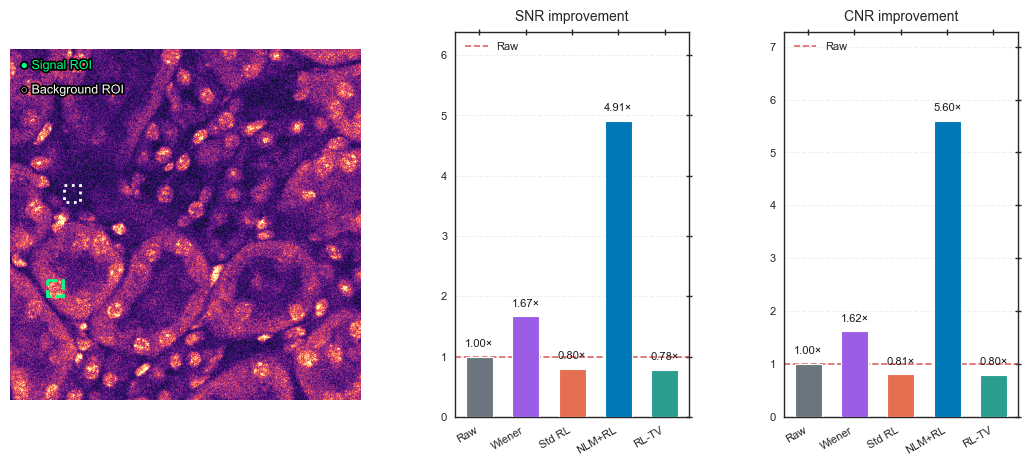

In [4]:

# =============================================================================
# SCIENTIFIC FIGURE v2 — RAW image with ROIs  +  SNR / CNR / FWHM bar charts
# Fixes:
#   1. SNR & CNR shown as relative improvement over Raw (removes NLM bias)
#   2. FWHM via Gaussian fit (physically motivated, robust to ringing)
#   3. Diffraction limit line on FWHM chart
# =============================================================================
import matplotlib.patheffects as pe
import matplotlib.patches as patches
from scipy.optimize import curve_fit

# ── ROI coordinates (pixels) — verify visually before use ────────────────────
Y_SIG, X_SIG = 348, 65   # centre of a bright isolated structure
Y_BG,  X_BG  = 210, 90   # centre of a dark/empty background region
HALF_ROI     = 12         # half-side of each square ROI [px]
PX_SIZE_UM   = MICROSCOPE["pixel_size"]

# Diffraction limit (Rayleigh criterion)
DIFF_LIMIT_UM = 0.61 * MICROSCOPE["wavelength"] / MICROSCOPE["NA"]

# ── Images — all percentile-normalised for fair comparison ───────────────────
risultati = {
    "Raw"    : raw_norm,
    "Wiener" : img_wiener,
    "Std RL" : img_rl_raw,
    "NLM+RL" : img_rl_nlm,
    "RL-TV"  : img_rl_tv,
}
labels = list(risultati.keys())
COLORS = ["#6C757D", "#9B5DE5", "#E76F51", "#0077B6", "#2A9D8F"]

# ── Metric helpers ────────────────────────────────────────────────────────────
def _roi(img, cy, cx, h):
    return img[cy-h:cy+h, cx-h:cx+h]

def snr_abs(img):
    """µ_signal / σ_background — absolute value."""
    return _roi(img, Y_SIG, X_SIG, HALF_ROI).mean() / \
           (_roi(img, Y_BG, X_BG, HALF_ROI).std() + 1e-9)

def cnr_abs(img):
    """(µ_sig − µ_bg) / σ_bg — absolute value."""
    mu_s  = _roi(img, Y_SIG, X_SIG, HALF_ROI).mean()
    bg    = _roi(img, Y_BG,  X_BG,  HALF_ROI)
    return np.abs(mu_s - bg.mean()) / (bg.std() + 1e-9)

def _gaussian(x, A, x0, sigma, bg):
    return A * np.exp(-(x - x0)**2 / (2 * sigma**2)) + bg

def fwhm_gaussian_um(img, y, x, window=50):
    """
    FWHM [µm] from a Gaussian fit on a horizontal line profile.
    Returns np.nan if the fit fails or sigma is unphysical.
    """
    start = max(0, x - window)
    end   = min(img.shape[1], x + window)
    prof  = img[y, start:end].astype(float)
    xs    = np.arange(len(prof))
    x_c   = x - start   # expected peak position within window

    # Initial parameter guess
    A0    = prof.max() - prof.min()
    bg0   = prof.min()
    sig0  = window / 6.0
    try:
        popt, _ = curve_fit(
            _gaussian, xs, prof,
            p0=[A0, x_c, sig0, bg0],
            bounds=([0, 0, 0.5, -np.inf],
                    [np.inf, len(prof), window, np.inf]),
            maxfev=4000
        )
        A_fit, x0_fit, sigma_fit, _ = popt
        # Sanity: amplitude must be positive, peak inside window
        if A_fit <= 0 or not (2 < x0_fit < len(prof) - 2):
            return np.nan
        return 2.3548 * sigma_fit * PX_SIZE_UM   # FWHM = 2√(2ln2)·σ
    except Exception:
        return np.nan

# ── Compute absolute metrics ──────────────────────────────────────────────────
snr_raw_val  = snr_abs(raw_norm)
cnr_raw_val  = cnr_abs(raw_norm)

snr_abs_vals  = [snr_abs(img)           for img in risultati.values()]
cnr_abs_vals  = [cnr_abs(img)           for img in risultati.values()]
fwhm_vals     = [fwhm_gaussian_um(img, Y_SIG, X_SIG) for img in risultati.values()]

# ── Relative SNR / CNR (ratio vs Raw — Raw = 1.0 baseline) ───────────────────
snr_rel = [v / (snr_raw_val + 1e-9) for v in snr_abs_vals]
cnr_rel = [v / (cnr_raw_val + 1e-9) for v in cnr_abs_vals]

print("── Metrics ──────────────────────────────────────────────────")
for i, lbl in enumerate(labels):
    fwhm_str = f"{fwhm_vals[i]:.3f} µm" if not np.isnan(fwhm_vals[i]) else "NaN"
    print(f"  {lbl:<10}  SNR_rel={snr_rel[i]:.2f}x  "
          f"CNR_rel={cnr_rel[i]:.2f}x  FWHM={fwhm_str}")
print(f"  Diffraction limit (Rayleigh): {DIFF_LIMIT_UM:.3f} µm")
print("─────────────────────────────────────────────────────────────")

metrics = {
    "SNR improvement\n(relative to Raw)":    (snr_rel,  "×", False),
    "CNR improvement\n(relative to Raw)":    (cnr_rel,  "×", False),
    "FWHM  [µm]\n(Gaussian fit)":            (fwhm_vals,"µm", True),
}

# ── Figure modificata ────────────────────────────────────────────────────────
sns.set_theme(style="white", context="paper")
fig = plt.figure(figsize=(13, 5)) # Ridotta la larghezza dato che manca FWHM
gs  = fig.add_gridspec(1, 3, wspace=0.35, width_ratios=[1.5, 1, 1])

# ── Panel 0 — RAW image con ROI ──────────────────────────────────────────────
ax_img = fig.add_subplot(gs[0])
ax_img.imshow(raw_norm, cmap="magma", vmin=0,
              vmax=np.percentile(raw_norm, 99.5), aspect="equal")
# Rimossi titolo e assi
ax_img.axis("off")

stroke = [pe.withStroke(linewidth=2.5, foreground="black")]

# Signal ROI
ax_img.add_patch(patches.Rectangle(
    (X_SIG - HALF_ROI, Y_SIG - HALF_ROI), 2*HALF_ROI, 2*HALF_ROI,
    linewidth=2, edgecolor="#00FF88", linestyle="--", fill=False, zorder=3))
# Background ROI
ax_img.add_patch(patches.Rectangle(
    (X_BG - HALF_ROI, Y_BG - HALF_ROI), 2*HALF_ROI, 2*HALF_ROI,
    linewidth=2, edgecolor="white", linestyle=":", fill=False, zorder=3))

ax_img.text(0.03, 0.97, "● Signal ROI", transform=ax_img.transAxes,
            fontsize=9, color="#00FF88", va="top", path_effects=stroke)
ax_img.text(0.03, 0.90, "○ Background ROI", transform=ax_img.transAxes,
            fontsize=9, color="white", va="top", path_effects=stroke)

# ── Panels 1-2 — Bar charts (solo SNR e CNR) ──────────────────────────────────
# Filtriamo solo le metriche richieste
metrics_short = {k: v for k, v in metrics.items() if "FWHM" not in k}
x_pos = np.arange(len(labels))

for col, (m_name, (m_vals, unit, lower_is_better)) in enumerate(metrics_short.items()):
    ax = fig.add_subplot(gs[col + 1])

    ax.bar(x_pos, m_vals, color=COLORS, edgecolor="white",
           linewidth=0.8, width=0.58, zorder=3)

    # Linea riferimento Raw
    ax.axhline(1.0, color="#D62828", linestyle="--",
               linewidth=1.2, alpha=0.7, label="Raw", zorder=2)
    ax.legend(fontsize=8, frameon=False, loc="upper left")

    # Y-axis limits
    ax.set_ylim(0, max(m_vals) * 1.3)

    # Valori sopra le barre
    for j, val in enumerate(m_vals):
        ax.text(j, val + 0.02 * ax.get_ylim()[1],
                f"{val:.2f}{unit}", ha="center", va="bottom",
                fontsize=8, color="#1a1a1a")

    # Griglia e assi
    ax.yaxis.grid(True, linestyle="--", alpha=0.30, zorder=0)
    ax.set_axisbelow(True)
    
    # Titolo normale (non bold)
    ax.set_title(m_name.split('\n')[0], fontsize=10, pad=8)
    
    ax.set_xticks(x_pos)
    ax.set_xticklabels(labels, fontsize=8.5, rotation=30, ha="right")
    
    # Abilitazione assi su tutti i lati
    ax.tick_params(axis="both", which="major", labelsize=8, 
                   top=True, right=True, direction="inout")
    
    # Rimuoviamo il despine automatico per mantenere gli assi chiusi
    # sns.despine(ax=ax) 

# ── Salvataggio ──────────────────────────────────────────────────────────────
cartella_salvataggio = "/Users/francesco/Repositories /noise_images/IMM"
save_path = os.path.join(cartella_salvataggio, "SNR_CNR_only.png")
plt.savefig(save_path, dpi=300, bbox_inches="tight", facecolor="white")
print(f"✅ Salvato in: {save_path}")
plt.show()